# 05: TabNet categorical embeddings vs one-hot encoding

**Person B | German Credit | Paired 5×5 repeated stratified CV**

This ablation compares two ways of encoding the **same 13 categorical and 7 numerical features** using the **same TabNet architecture, folds, validation split, seeds, training settings and metrics**:

1. **Embeddings**: integer-encoded categories with TabNet's learned categorical embeddings.
2. **One-hot**: one-hot encoded categories, no learned categorical embeddings.

All preprocessing is fit **only on each fold's inner training set**, avoiding validation/test leakage. The notebook runs both configurations for each fold and saves progress after each completed run. A fair comparison is based on paired fold differences, not the earlier separately trained TabNet baseline.

**Runtime:** approximately 30–120+ minutes depending on Colab hardware and early stopping. The full experiment trains 50 models. Set `QUICK_TEST=True` to run one fold per configuration first; change it to `False` for final results.


## Cell 1: Install

## Cell 2: Locate or upload your full team repository ZIP

In [1]:
from pathlib import Path
import os, sys

# Run from anywhere inside the repo (locally, or in Colab after cloning it).
ROOT = Path.cwd().resolve()
while not (ROOT / "common" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Start the notebook from inside the repository folder.")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "results" / "person_b"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)

Repository: /home/claude/work


## Cell 3: Imports, configuration and helpers

In [2]:
import gc, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from common.data import load_german, german_cv_splits
from common.metrics import all_metrics, german_cost

QUICK_TEST = False     # Set True to test 1 fold per encoding before full run
MAX_EPOCHS = 80
PATIENCE = 12

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def build_tabnet(seed,cat_idxs=None,cat_dims=None):
    return TabNetClassifier(
        n_d=8,n_a=8,n_steps=3,gamma=1.3,
        cat_idxs=cat_idxs or [],cat_dims=cat_dims or [],
        cat_emb_dim=2,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=0.02),
        mask_type="entmax",seed=seed,verbose=0,device_name="auto"
    )

df=load_german()
X=df.drop(columns=["bad"])
y=df["bad"].to_numpy(dtype=int)
categorical_cols=X.select_dtypes(include=["object","category"]).columns.tolist()
numerical_cols=X.select_dtypes(include=["number"]).columns.tolist()
assert len(categorical_cols)==13 and len(numerical_cols)==7, (categorical_cols,numerical_cols)
folds=list(german_cv_splits(df))
assert len(folds)==25, len(folds)
print("Data:",df.shape,"categorical:",len(categorical_cols),"numeric:",len(numerical_cols))
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")


Data: (1000, 21) categorical: 13 numeric: 7
Device: CPU


## Cell 4: Train the paired experiment

Every fold is evaluated twice. The script saves a metrics CSV and a prediction CSV **after each model**, so if Colab disconnects after a model finishes, you can recover the completed results from the session. Download the ZIP at the end; files in Colab's temporary runtime do **not** survive a full reset.

If you are rerunning in the same session, the code automatically skips rows already present in the output metrics CSV.


In [3]:
METRICS=OUT/"tabnet_encoding_ablation_metrics.csv"
PREDS=OUT/"tabnet_encoding_ablation_predictions.csv"
metrics_rows=pd.read_csv(METRICS).to_dict("records") if METRICS.exists() else []
prediction_rows=pd.read_csv(PREDS).to_dict("records") if PREDS.exists() else []
completed={(int(r["repeat"]),int(r["fold"]),str(r["encoding"])) for r in metrics_rows}
selected_folds=folds[:1] if QUICK_TEST else folds

for repeat,fold,train_idx,test_idx in selected_folds:
    seed=42+int(repeat)*5+int(fold)
    inner_train_idx, val_idx=train_test_split(
        train_idx,test_size=0.2,stratify=y[train_idx],random_state=seed
    )
    fit_raw=X.iloc[inner_train_idx]
    val_raw=X.iloc[val_idx]
    test_raw=X.iloc[test_idx]
    y_fit,y_val,y_test=y[inner_train_idx],y[val_idx],y[test_idx]

    for encoding in ("embeddings","one_hot"):
        key=(int(repeat),int(fold),encoding)
        if key in completed:
            print("Skipping completed:",key,flush=True)
            continue
        set_seed(seed)

        if encoding=="embeddings":
            scaler=StandardScaler()
            fit_num=scaler.fit_transform(fit_raw[numerical_cols]).astype("float32")
            val_num=scaler.transform(val_raw[numerical_cols]).astype("float32")
            test_num=scaler.transform(test_raw[numerical_cols]).astype("float32")
            train_cats=[]; val_cats=[]; test_cats=[]; cat_dims=[]
            for col in categorical_cols:
                vocabulary={v:j+1 for j,v in enumerate(fit_raw[col].astype(str).unique())}
                def enc(s):
                    return s.astype(str).map(vocabulary).fillna(0).to_numpy(dtype="float32")
                train_cats.append(enc(fit_raw[col]))
                val_cats.append(enc(val_raw[col]))
                test_cats.append(enc(test_raw[col]))
                cat_dims.append(len(vocabulary)+1)
            X_fit=np.column_stack([fit_num]+train_cats).astype("float32")
            X_val=np.column_stack([val_num]+val_cats).astype("float32")
            X_test=np.column_stack([test_num]+test_cats).astype("float32")
            cat_idxs=list(range(len(numerical_cols),X_fit.shape[1]))
            model=build_tabnet(seed,cat_idxs,cat_dims)
        else:
            processor=ColumnTransformer([
                ("num",StandardScaler(),numerical_cols),
                ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),categorical_cols)
            ])
            X_fit=processor.fit_transform(fit_raw).astype("float32")
            X_val=processor.transform(val_raw).astype("float32")
            X_test=processor.transform(test_raw).astype("float32")
            model=build_tabnet(seed)

        start=time.time()
        model.fit(
            X_train=X_fit,y_train=y_fit,
            eval_set=[(X_val,y_val)],eval_name=["val"],eval_metric=["logloss"],
            max_epochs=MAX_EPOCHS,patience=PATIENCE,
            batch_size=256,virtual_batch_size=64,
            num_workers=0,drop_last=False
        )
        probs=model.predict_proba(X_test)[:,1]
        m=all_metrics(y_test,probs)
        m.update(dataset="German Credit",model="TabNet",encoding=encoding,
                 repeat=int(repeat),fold=int(fold),seed=int(seed),
                 input_features=int(X_fit.shape[1]),
                 train_seconds=round(time.time()-start,2),
                 cost_05=german_cost(y_test,probs>=0.5),
                 cost_0167=german_cost(y_test,probs>=1/6))
        metrics_rows.append(m)
        prediction_rows.extend({
            "encoding":encoding,"repeat":int(repeat),"fold":int(fold),
            "row_index":int(i),"actual":int(actual),
            "predicted_probability":float(p)
        } for i,actual,p in zip(test_idx,y_test,probs))
        pd.DataFrame(metrics_rows).to_csv(METRICS,index=False)
        pd.DataFrame(prediction_rows).to_csv(PREDS,index=False)
        completed.add(key)
        print(f"Repeat {repeat+1}/5 Fold {fold+1}/5 {encoding}: "
              f"PR-AUC={m['pr_auc']:.4f}, Brier={m['brier']:.4f}, "
              f"Cost={m['cost_0167']:.4f}, {m['train_seconds']:.1f}s",flush=True)
        del model
        gc.collect()

print("\nCompleted models:",len(pd.read_csv(METRICS)))
print("Saved to:",METRICS)



Early stopping occurred at epoch 22 with best_epoch = 10 and best_val_logloss = 0.56213
Repeat 1/5 Fold 1/5 embeddings: PR-AUC=0.4758, Brier=0.1985, Cost=0.7700, 1.7s



Early stopping occurred at epoch 27 with best_epoch = 15 and best_val_logloss = 0.53918
Repeat 1/5 Fold 1/5 one_hot: PR-AUC=0.4692, Brier=0.1849, Cost=0.4950, 1.2s



Early stopping occurred at epoch 20 with best_epoch = 8 and best_val_logloss = 0.58267
Repeat 1/5 Fold 2/5 embeddings: PR-AUC=0.4690, Brier=0.1973, Cost=0.7050, 0.8s



Early stopping occurred at epoch 22 with best_epoch = 10 and best_val_logloss = 0.57771
Repeat 1/5 Fold 2/5 one_hot: PR-AUC=0.5203, Brier=0.1984, Cost=0.6600, 1.0s



Early stopping occurred at epoch 18 with best_epoch = 6 and best_val_logloss = 0.59017
Repeat 1/5 Fold 3/5 embeddings: PR-AUC=0.4378, Brier=0.1897, Cost=0.5950, 0.8s



Early stopping occurred at epoch 32 with best_epoch = 20 and best_val_logloss = 0.51516
Repeat 1/5 Fold 3/5 one_hot: PR-AUC=0.5366, Brier=0.1844, Cost=0.7550, 1.5s


... (41 outputs left out)


Early stopping occurred at epoch 40 with best_epoch = 28 and best_val_logloss = 0.52837
Repeat 5/5 Fold 4/5 one_hot: PR-AUC=0.5777, Brier=0.1762, Cost=0.5950, 2.1s



Early stopping occurred at epoch 19 with best_epoch = 7 and best_val_logloss = 0.59665
Repeat 5/5 Fold 5/5 embeddings: PR-AUC=0.4229, Brier=0.2027, Cost=0.6900, 0.8s



Early stopping occurred at epoch 26 with best_epoch = 14 and best_val_logloss = 0.56292
Repeat 5/5 Fold 5/5 one_hot: PR-AUC=0.4522, Brier=0.1969, Cost=0.7050, 1.1s



Completed models: 50
Saved to: /home/claude/work/results/person_b/tabnet_encoding_ablation_metrics.csv


## Cell 5: Summary, paired fold differences and figures

=== Mean ± SD by encoding ===
            pr_auc         roc_auc           brier            rmse             mae         cost_05         cost_0167         train_seconds        
              mean     std    mean     std    mean     std    mean     std    mean     std    mean     std      mean     std          mean     std
encoding                                                                                                                                          
embeddings  0.4501  0.0516  0.6580  0.0515  0.2009  0.0136  0.4480  0.0152  0.3900  0.0190  1.3340  0.1417    0.7034  0.0671        1.1340  0.2875
one_hot     0.5025  0.0600  0.7115  0.0429  0.1903  0.0101  0.4361  0.0114  0.3597  0.0214  1.3186  0.1433    0.6506  0.0725        1.6076  0.4523

=== Paired mean difference (one-hot minus embeddings) ===
pr_auc_one_hot_minus_embeddings           0.0524
roc_auc_one_hot_minus_embeddings          0.0534
brier_one_hot_minus_embeddings           -0.0106
rmse_one_hot_minus_embeddings

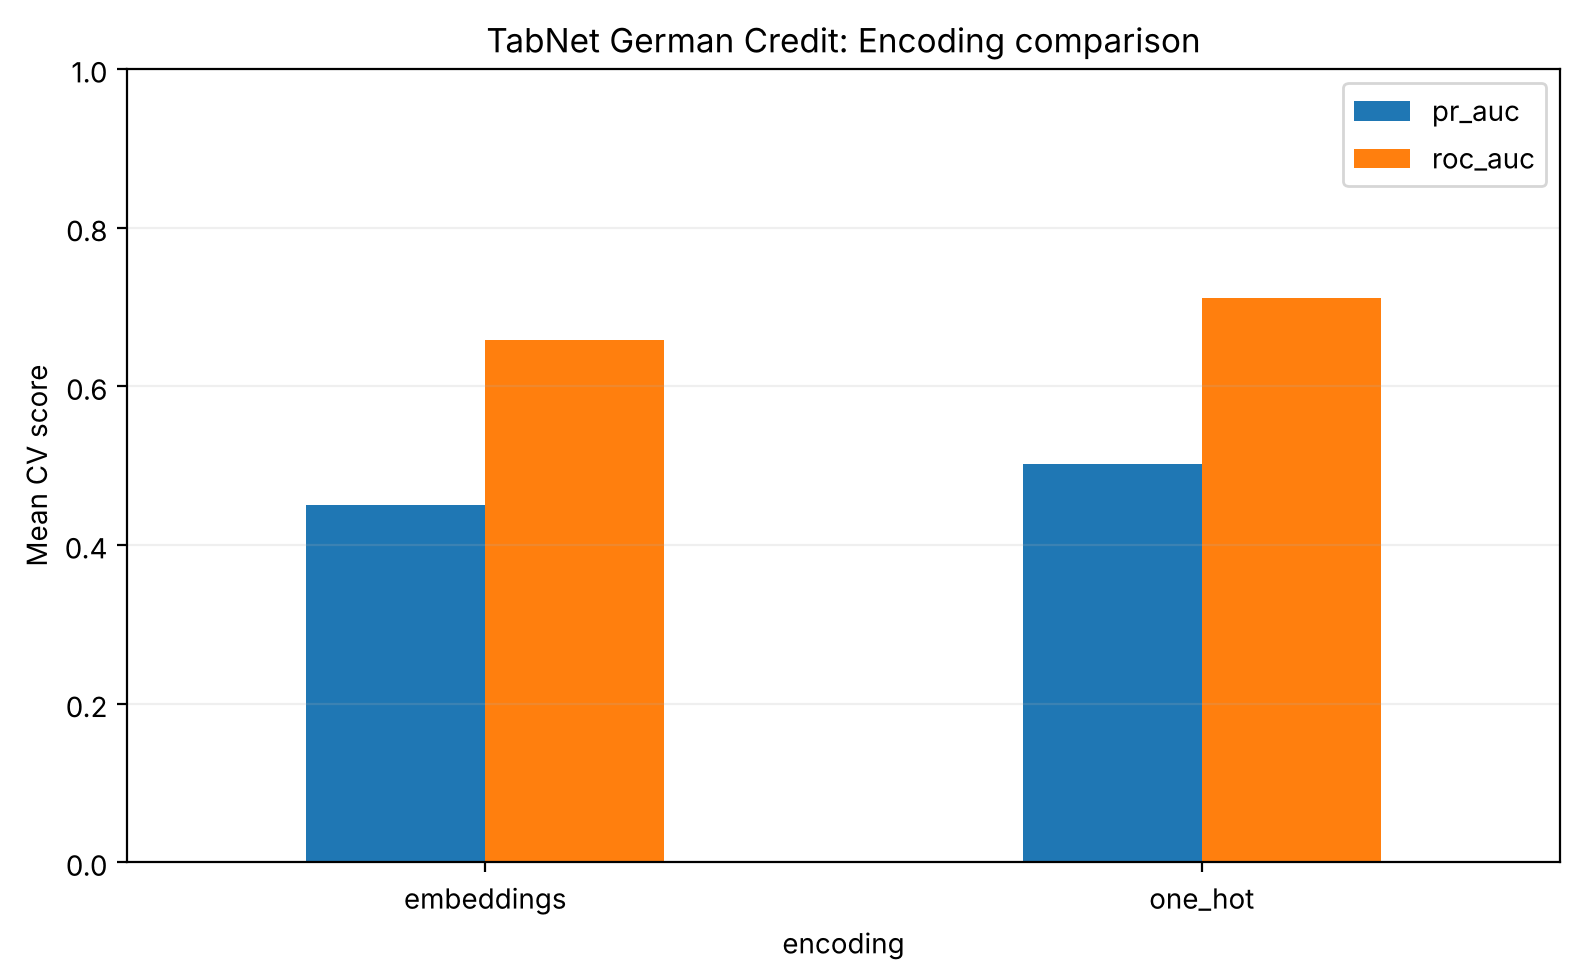

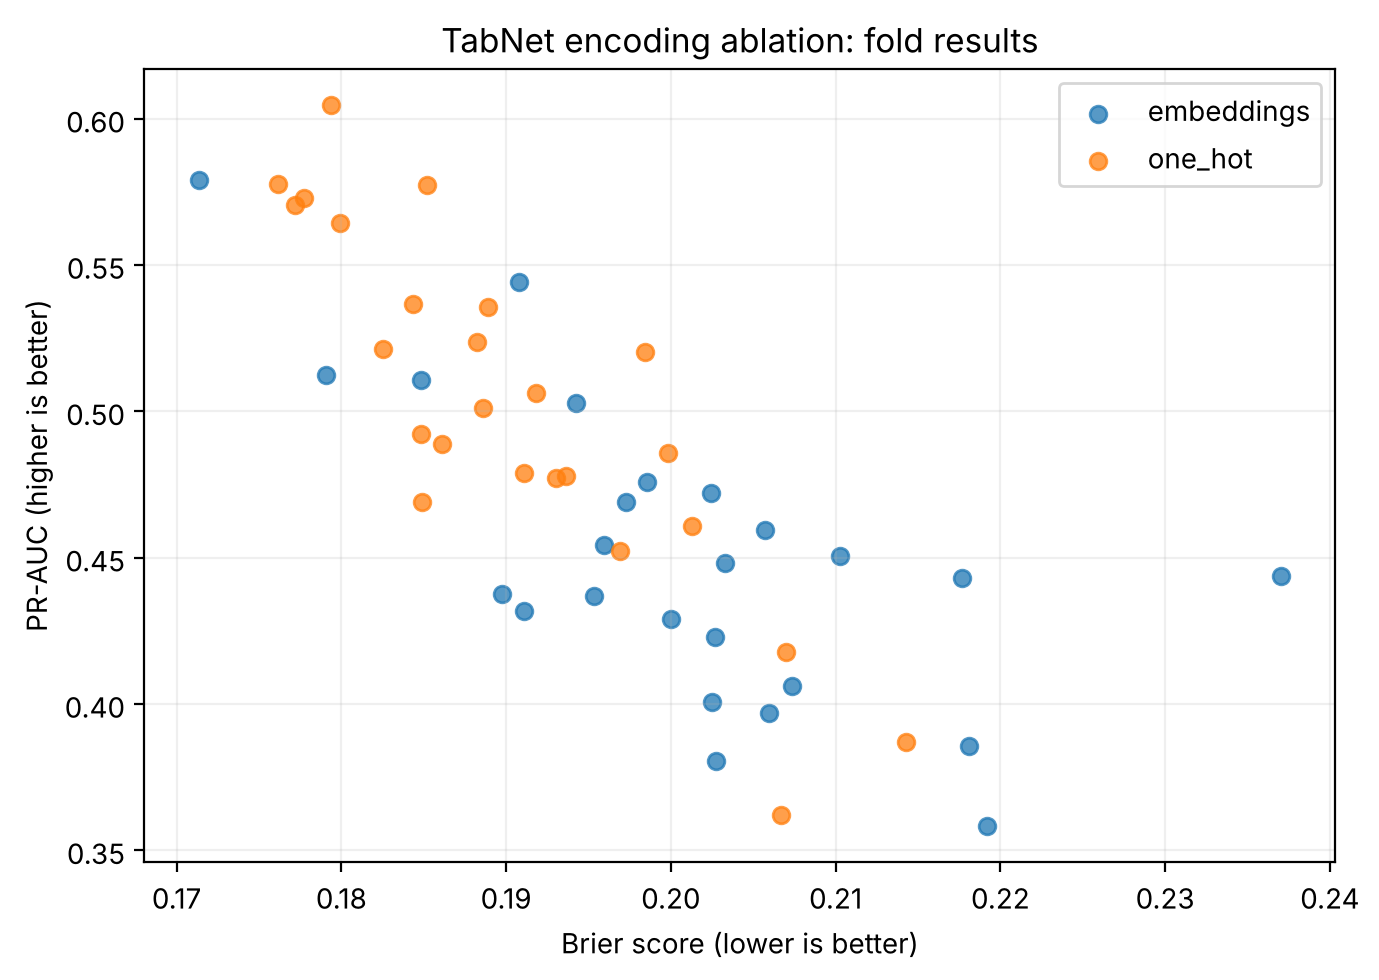


Note: these are overlapping repeated CV folds, not independent test sets.


In [4]:
results=pd.read_csv(METRICS)
expected=2 if QUICK_TEST else 50
if len(results)!=expected:
    raise ValueError(f"Expected {expected} models; found {len(results)}. Check training output.")

cols=["pr_auc","roc_auc","brier","rmse","mae","cost_05","cost_0167","train_seconds"]
summary=results.groupby("encoding")[cols].agg(["mean","std"])
summary.to_csv(OUT/"tabnet_encoding_ablation_summary.csv")
print("=== Mean ± SD by encoding ===")
print(summary.round(4).to_string())

paired=results.pivot(index=["repeat","fold"],columns="encoding",values=cols)
if paired.isna().any().any():
    raise ValueError("Missing one encoding for a fold")
differences=pd.DataFrame(index=paired.index)
for metric in cols:
    differences[f"{metric}_one_hot_minus_embeddings"]=(paired[(metric,"one_hot")]-
                                                       paired[(metric,"embeddings")])
differences.to_csv(OUT/"tabnet_encoding_ablation_paired_differences.csv")
print("\n=== Paired mean difference (one-hot minus embeddings) ===")
print(differences.mean().round(4).to_string())

fig,ax=plt.subplots(figsize=(8,5))
means=results.groupby("encoding")[["pr_auc","roc_auc"]].mean()
means.plot(kind="bar",ax=ax,rot=0)
ax.set(title="TabNet German Credit: Encoding comparison",ylabel="Mean CV score",ylim=(0,1))
ax.grid(axis="y",alpha=.2)
fig.tight_layout()
fig.savefig(FIG/"tabnet_encoding_auc_comparison.png",dpi=180)
plt.show()

fig,ax=plt.subplots(figsize=(7,5))
for label,grp in results.groupby("encoding"):
    ax.scatter(grp["brier"],grp["pr_auc"],label=label,alpha=.75)
ax.set(xlabel="Brier score (lower is better)",ylabel="PR-AUC (higher is better)",
       title="TabNet encoding ablation: fold results")
ax.grid(alpha=.2);ax.legend()
fig.tight_layout()
fig.savefig(FIG/"tabnet_encoding_fold_scatter.png",dpi=180)
plt.show()

print("\nNote: these are overlapping repeated CV folds, not independent test sets.")


## Cell 6: Generate report-ready interpretation (automatically based on results)

In [5]:
means=results.groupby("encoding")[cols].mean()
emb=means.loc["embeddings"]
oh=means.loc["one_hot"]
winner_pr="one-hot" if oh["pr_auc"]>emb["pr_auc"] else "embeddings"
winner_brier="one-hot" if oh["brier"]<emb["brier"] else "embeddings"
notes=f'''# TabNet German Credit: categorical embeddings vs one-hot

## Design
Paired repeated stratified 5-fold CV × 5 repeats ({len(results)} model fits).
Both representations used the same folds, inner validation split, TabNet architecture,
training hyperparameters, seed per fold, and metrics. Preprocessing was fitted only
on the inner training partition.

- Embeddings: {len(numerical_cols)} standardized numeric columns and {len(categorical_cols)} integer-encoded categorical columns, learned 2-dimensional categorical embeddings.
- One-hot: standardized numeric columns plus one-hot encoded categorical columns.

## Results (means across folds)
- PR-AUC: embeddings {emb['pr_auc']:.4f}; one-hot {oh['pr_auc']:.4f}. Higher is better; {winner_pr} scored higher.
- ROC-AUC: embeddings {emb['roc_auc']:.4f}; one-hot {oh['roc_auc']:.4f}.
- Brier: embeddings {emb['brier']:.4f}; one-hot {oh['brier']:.4f}. Lower is better; {winner_brier} scored lower.
- Mean cost at threshold 1/6: embeddings {emb['cost_0167']:.4f}; one-hot {oh['cost_0167']:.4f}.

## Interpretation limits
This is an encoding ablation for this particular dataset, model configuration and
training budget, not proof that one encoding is always superior.
Repeated CV folds overlap across repeats; avoid treating the 25 differences as
25 independent datasets. Cost threshold 1/6 is theoretically optimal only for
well-calibrated probabilities under the specified 5:1 error costs.
'''
(OUT/"tabnet_encoding_ablation_interpretation.md").write_text(notes,encoding="utf-8")
print(notes)


# TabNet German Credit: categorical embeddings vs one-hot

## Design
Paired repeated stratified 5-fold CV × 5 repeats (50 model fits).
Both representations used the same folds, inner validation split, TabNet architecture,
training hyperparameters, seed per fold, and metrics. Preprocessing was fitted only
on the inner training partition.

- Embeddings: 7 standardized numeric columns and 13 integer-encoded categorical columns, learned 2-dimensional categorical embeddings.
- One-hot: standardized numeric columns plus one-hot encoded categorical columns.

## Results (means across folds)
- PR-AUC: embeddings 0.4501; one-hot 0.5025. Higher is better; one-hot scored higher.
- ROC-AUC: embeddings 0.6580; one-hot 0.7115.
- Brier: embeddings 0.2009; one-hot 0.1903. Lower is better; one-hot scored lower.
- Mean cost at threshold 1/6: embeddings 0.7034; one-hot 0.6506.

## Interpretation limits
This is an encoding ablation for this particular dataset, model configuration and
training budget, not p

## Cell 7: ZIP and download all outputs

## GitHub upload structure

- Notebook: `person_b/05_tabnet_encoding_ablation.ipynb`
- CSV and Markdown outputs: `results/person_b/`
- PNG plots: `results/person_b/figures/`

Do **not** upload the entire results ZIP if you have already extracted and committed the individual files. This experiment does not modify teammates' code or results.
